<a href="https://colab.research.google.com/github/VER2E/NEUR3002-In-class-Activities/blob/main/ICASept23.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


CRICKET CERCAL SYSTEM POPULATION CODING

STIMULUS
-----------------------------
Actual airflow direction: 60.00°

NEURAL POPULATION
-----------------------------
Neuron 1: Preferred direction = 0° | Firing rate = 20.56 Hz | INHIBITED
Neuron 2: Preferred direction = 45° | Firing rate = 47.30 Hz | INHIBITED
Neuron 3: Preferred direction = 90° | Firing rate = 40.04 Hz | INHIBITED
Neuron 4: Preferred direction = 135° | Firing rate = 12.47 Hz | INHIBITED
Neuron 5: Preferred direction = 180° | Firing rate = 1.43 Hz | ACTIVE
Neuron 6: Preferred direction = 225° | Firing rate = 0.06 Hz | ACTIVE
Neuron 7: Preferred direction = 270° | Firing rate = 0.19 Hz | ACTIVE
Neuron 8: Preferred direction = 315° | Firing rate = 3.29 Hz | ACTIVE

POPULATION VECTOR BEFORE INHIBITION
-----------------------------
Direction: 60.00°
Magnitude: 92.07

POPULATION VECTOR AFTER INHIBITION
-----------------------------
Direction: 288.43°
Magnitude: 2.70

EFFECT OF INHIBITION
-----------------------------
Change in 

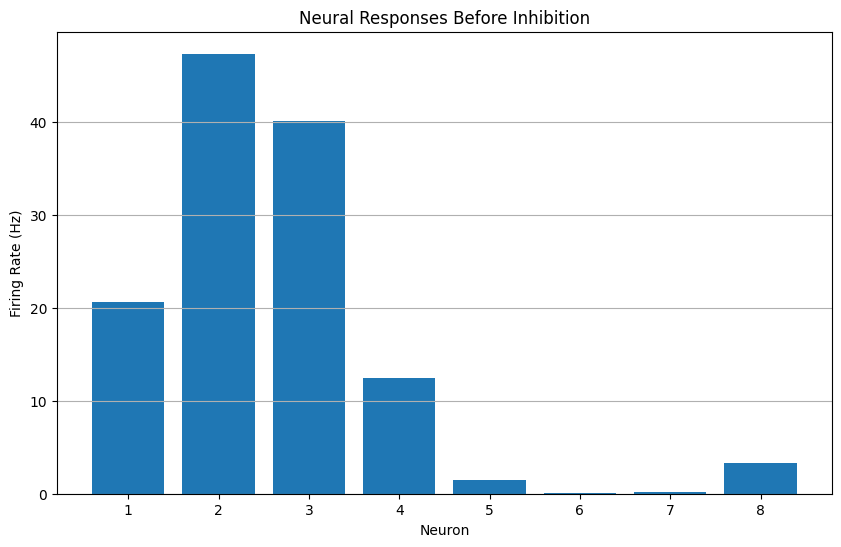

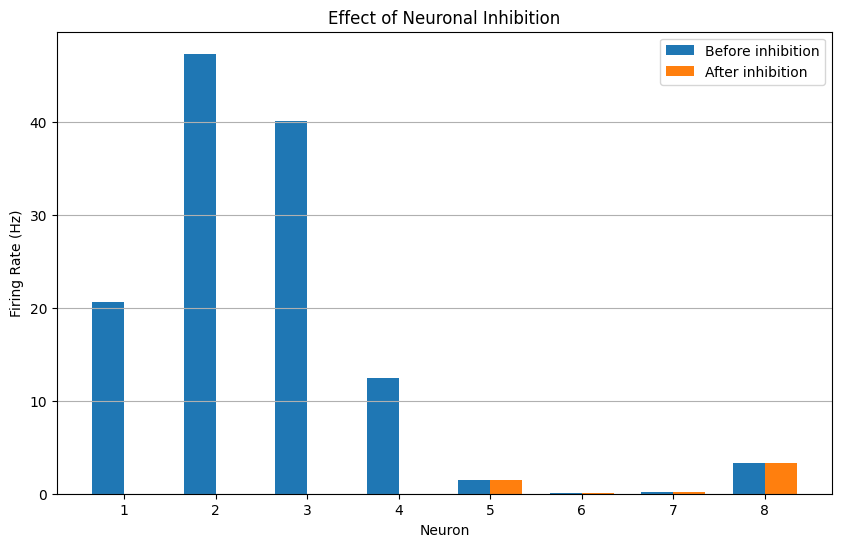

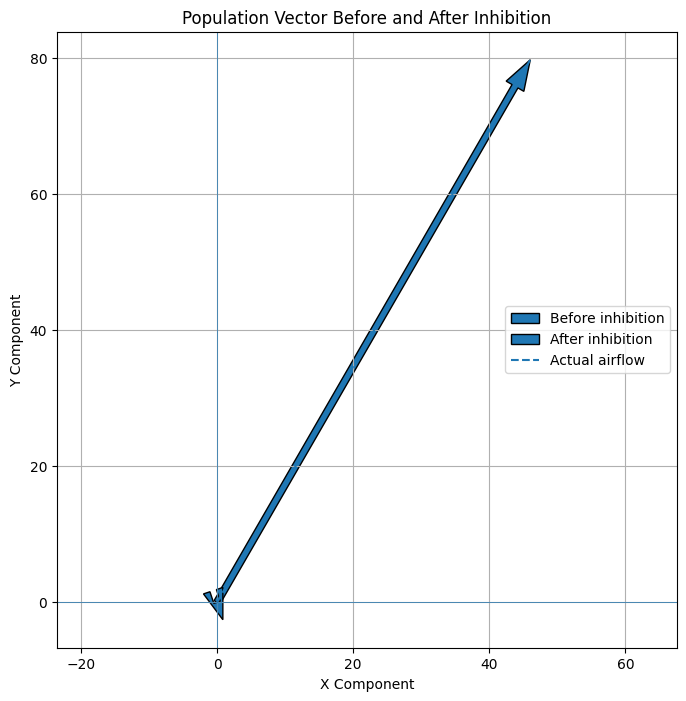


SUMMARY
Stimulus direction: 60.00°
Population direction before inhibition: 60.00°
Population direction after inhibition: 288.43°
Direction changed by: -131.57°
Population magnitude changed by: -89.38


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


# ============================================================
# POPULATION CODING IN THE CRICKET CERCAL SYSTEM
# ============================================================
#
# Purpose:
# Analyze how activity across a population of sensory neurons
# represents the direction of an airflow stimulus.
#
# The program can:
#   1. Use simulated data
#   2. Import real neural data from a CSV file
#   3. Calculate the population vector
#   4. Inhibit selected neurons
#   5. Recalculate the population vector
#   6. Compare the normal and inhibited populations
#
# ============================================================


# ============================================================
# 1. USER SETTINGS
# ============================================================

# Direction of the airflow stimulus
stimulus_direction = 60


# Choose data source:
#
# False = simulated data
# True  = real experimental data
#
USE_REAL_DATA = False


# Name of real data file
DATA_FILE = "cercal_neural_data.csv"


# Neurons to inhibit
#
# Python uses zero-based indexing:
#
# 0 = Neuron 1
# 1 = Neuron 2
# 2 = Neuron 3
# etc.
#
# Example:
# [0, 1, 2, 3] inhibits neurons 1-4

INHIBITED_NEURONS = [0, 1, 2, 3]


# ============================================================
# 2. SIMULATED DATA
# ============================================================

preferred_directions = np.array([
    0,
    45,
    90,
    135,
    180,
    225,
    270,
    315
])


max_firing_rate = 50
tuning_width = 45


def circular_difference(angle1, angle2):
    """
    Finds the smallest difference between two angles.

    This accounts for the fact that 0° and 360°
    represent the same direction.
    """

    difference = np.abs(angle1 - angle2)

    return np.minimum(
        difference,
        360 - difference
    )


def tuning_curve(
        stimulus,
        preferred_direction):

    """
    Simulates the firing rate of a neuron.

    A neuron fires most strongly when the stimulus
    is close to its preferred direction.
    """

    difference = circular_difference(
        stimulus,
        preferred_direction
    )

    firing_rate = (
        max_firing_rate *
        np.exp(
            -(difference ** 2) /
            (2 * tuning_width ** 2)
        )
    )

    return firing_rate


# ============================================================
# 3. LOAD DATA
# ============================================================

if USE_REAL_DATA:

    # --------------------------------------------------------
    # Import experimental data
    # --------------------------------------------------------

    data = pd.read_csv(DATA_FILE)

    preferred_directions = (
        data["Preferred_Direction"].to_numpy()
    )

    responses = (
        data["Firing_Rate"].to_numpy()
    )

else:

    # --------------------------------------------------------
    # Generate simulated neural responses
    # --------------------------------------------------------

    responses = np.array([
        tuning_curve(
            stimulus_direction,
            direction
        )
        for direction in preferred_directions
    ])


# ============================================================
# 4. FUNCTION TO CALCULATE POPULATION VECTOR
# ============================================================

def calculate_population_vector(
        preferred_directions,
        responses):

    """
    Calculates the population vector from
    neuronal firing rates.

    Each neuron's firing rate is weighted by
    its preferred direction.
    """

    # Convert degrees to radians
    radians = np.deg2rad(
        preferred_directions
    )

    # Calculate each neuron's vector components
    x_components = (
        responses *
        np.cos(radians)
    )

    y_components = (
        responses *
        np.sin(radians)
    )

    # Add all neurons together
    population_x = np.sum(
        x_components
    )

    population_y = np.sum(
        y_components
    )

    # Calculate population-vector direction
    direction = (
        np.rad2deg(
            np.arctan2(
                population_y,
                population_x
            )
        )
        % 360
    )

    # Calculate population-vector magnitude
    magnitude = np.sqrt(
        population_x ** 2 +
        population_y ** 2
    )

    return (
        direction,
        magnitude,
        population_x,
        population_y
    )


# ============================================================
# 5. CALCULATE ORIGINAL POPULATION VECTOR
# ============================================================

original_direction, original_magnitude, original_x, original_y = \
    calculate_population_vector(
        preferred_directions,
        responses
    )


# ============================================================
# 6. INHIBIT SELECTED NEURONS
# ============================================================

# Make a copy so the original neural data
# remains unchanged.

inhibited_responses = responses.copy()


# Set the firing rate of selected neurons to zero

inhibited_responses[
    INHIBITED_NEURONS
] = 0


# ============================================================
# 7. CALCULATE NEW POPULATION VECTOR
# ============================================================

inhibited_direction, inhibited_magnitude, inhibited_x, inhibited_y = \
    calculate_population_vector(
        preferred_directions,
        inhibited_responses
    )


# ============================================================
# 8. CALCULATE EFFECT OF INHIBITION
# ============================================================

direction_change = (
    inhibited_direction -
    original_direction
)


# Correct for circular direction
if direction_change > 180:
    direction_change -= 360

if direction_change < -180:
    direction_change += 360


magnitude_change = (
    inhibited_magnitude -
    original_magnitude
)


# ============================================================
# 9. PRINT RESULTS
# ============================================================

print()
print("=" * 60)
print("CRICKET CERCAL SYSTEM POPULATION CODING")
print("=" * 60)

print()

print("STIMULUS")
print("-----------------------------")
print(
    f"Actual airflow direction: "
    f"{stimulus_direction:.2f}°"
)

print()

print("NEURAL POPULATION")
print("-----------------------------")

for i in range(len(responses)):

    status = "INHIBITED" if i in INHIBITED_NEURONS else "ACTIVE"

    print(
        f"Neuron {i + 1}: "
        f"Preferred direction = "
        f"{preferred_directions[i]:.0f}° | "
        f"Firing rate = "
        f"{responses[i]:.2f} Hz | "
        f"{status}"
    )


print()

print("POPULATION VECTOR BEFORE INHIBITION")
print("-----------------------------")

print(
    f"Direction: "
    f"{original_direction:.2f}°"
)

print(
    f"Magnitude: "
    f"{original_magnitude:.2f}"
)


print()

print("POPULATION VECTOR AFTER INHIBITION")
print("-----------------------------")

print(
    f"Direction: "
    f"{inhibited_direction:.2f}°"
)

print(
    f"Magnitude: "
    f"{inhibited_magnitude:.2f}"
)


print()

print("EFFECT OF INHIBITION")
print("-----------------------------")

print(
    f"Change in population direction: "
    f"{direction_change:.2f}°"
)

print(
    f"Change in population magnitude: "
    f"{magnitude_change:.2f}"
)


# ============================================================
# 10. PLOT NEURAL RESPONSES
# ============================================================

plt.figure(figsize=(10, 6))

neuron_numbers = np.arange(
    1,
    len(responses) + 1
)

plt.bar(
    neuron_numbers,
    responses
)

plt.xlabel("Neuron")
plt.ylabel("Firing Rate (Hz)")

plt.title(
    "Neural Responses Before Inhibition"
)

plt.xticks(
    neuron_numbers
)

plt.grid(
    axis="y"
)

plt.show()


# ============================================================
# 11. PLOT RESPONSES BEFORE AND AFTER INHIBITION
# ============================================================

plt.figure(figsize=(10, 6))

width = 0.35

plt.bar(
    neuron_numbers - width / 2,
    responses,
    width=width,
    label="Before inhibition"
)

plt.bar(
    neuron_numbers + width / 2,
    inhibited_responses,
    width=width,
    label="After inhibition"
)

plt.xlabel("Neuron")
plt.ylabel("Firing Rate (Hz)")

plt.title(
    "Effect of Neuronal Inhibition"
)

plt.xticks(
    neuron_numbers
)

plt.legend()

plt.grid(
    axis="y"
)

plt.show()


# ============================================================
# 12. PLOT POPULATION VECTORS
# ============================================================

plt.figure(figsize=(8, 8))


# ------------------------------------------------------------
# Original population vector
# ------------------------------------------------------------

plt.arrow(
    0,
    0,
    original_x,
    original_y,
    length_includes_head=True,
    width=1,
    label="Before inhibition"
)


# ------------------------------------------------------------
# Inhibited population vector
# ------------------------------------------------------------

plt.arrow(
    0,
    0,
    inhibited_x,
    inhibited_y,
    length_includes_head=True,
    width=1,
    label="After inhibition"
)


# ------------------------------------------------------------
# Actual stimulus direction
# ------------------------------------------------------------

stimulus_length = max(
    original_magnitude,
    inhibited_magnitude
)


stimulus_x = (
    stimulus_length *
    np.cos(
        np.deg2rad(
            stimulus_direction
        )
    )
)


stimulus_y = (
    stimulus_length *
    np.sin(
        np.deg2rad(
            stimulus_direction
        )
    )
)


plt.plot(
    [0, stimulus_x],
    [0, stimulus_y],
    linestyle="--",
    label="Actual airflow"
)


plt.xlabel("X Component")
plt.ylabel("Y Component")

plt.title(
    "Population Vector Before and After Inhibition"
)

plt.axhline(
    0,
    linewidth=0.5
)

plt.axvline(
    0,
    linewidth=0.5
)

plt.legend()

plt.grid()

plt.axis("equal")

plt.show()


# ============================================================
# 13. SUMMARY
# ============================================================

print()
print("=" * 60)
print("SUMMARY")
print("=" * 60)

print(
    f"Stimulus direction: "
    f"{stimulus_direction:.2f}°"
)

print(
    f"Population direction before inhibition: "
    f"{original_direction:.2f}°"
)

print(
    f"Population direction after inhibition: "
    f"{inhibited_direction:.2f}°"
)

print(
    f"Direction changed by: "
    f"{direction_change:.2f}°"
)

print(
    f"Population magnitude changed by: "
    f"{magnitude_change:.2f}"
)